# 1. Introduction

This project covers an analysis of the Planetary Systems dataset obtained from the NASA Exoplanet Archive. The data contains information about extrasolar planets detected through various methods (such as transit, radial velocity, direct imaging, etc.) and by various facilities.

Tools used in this project include: Python, Jupyter Notebook, Pandas, Numpy, and Matplotlib.

Key questions:
1. What is the most common detection method?
2. How have exoplanet detections changed over time?
3. What are the distributions of discovered exoplanet masses, radii, and orbital periods?
4. How are the masses, radii, and orbital periods of discovered exoplanets related?
5. Do certain detection methods favour certain types of exoplanet?

# 2. Data Loading

This section covers loading the NASA Exoplanet Archive Planetary Systems dataset so that it can be utilised in the analyis.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

First, we read the dataset obtained from the NASA Exoplanet Archive into a pandas dataframe.

In [2]:
# Read csv file into a Pandas dataframe
df = pd.read_csv('NASA_exoplanet_archive_planetary_systems.csv', comment = '#')

# Display the first few rows to confirm loading and understand dataset structure
df.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-07-23,2011-08,2014-07-23
1,11 Com b,11 Com,1,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2023-09-19,2023-12,2023-09-19
2,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,0,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-05-14,2008-01,2014-05-14
3,11 UMi b,11 UMi,1,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,0,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-09-04,2017-03,2018-09-06
4,11 UMi b,11 UMi,0,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,0,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-04-25,2011-08,2014-07-23


In [3]:
# Examine the size of the dataset
df.shape

(40106, 92)

# 3. Data Cleaning

The next step is to examine and clean the dataset so that it can be used in the analysis. The dataset has two variables that can help with data cleaning and data integrity: default_flag and pl_controv_flag. The data as it stands contains multiple entries for each planet potentially due to multiple detections using different detection methods - e.g.: transit, radial velocity, etc - which could skew any analysis. The default_flag variable indicates which entry for each planet has been selected by NASA to represent the default set of values for that planet. For this analysis, we will be using these default entries. The pl_controv_flag variable indicates whether the entry has been flagged by NASA as being controversial. To avoid outliers that could potentially skew the data, we will remove these controversial entries.

In [4]:
# Create new dataframe with only default entries and without controversial entries
df_clean = df[(df['default_flag'] == 1) & (df['pl_controv_flag'] == 0)]

In [5]:
print("Original Dataset:")
print(" Rows:", len(df))
print(" Columns:", len(df.columns))

print(" Missing planet names:", df['pl_name'].isna().sum())
print(" Duplicate planet names:", df['pl_name'].duplicated().sum())
print(" Unique planets:", df['pl_name'].nunique())

print("\n")

print("New Dataset:")
print(" Rows:", len(df_clean))
print(" Columns:", len(df_clean.columns))
print(" Missing planet names:", df_clean['pl_name'].isna().sum())
print(" Duplicate planet names:", df_clean['pl_name'].duplicated().sum())
print(" Unique planets:", df_clean['pl_name'].nunique())

Original Dataset:
 Rows: 40106
 Columns: 92
 Missing planet names: 0
 Duplicate planet names: 33752
 Unique planets: 6354


New Dataset:
 Rows: 6296
 Columns: 92
 Missing planet names: 0
 Duplicate planet names: 0
 Unique planets: 6296


A large proportion of the data has been removed, but there were many duplicate entries in the original dataset. There were originally only 6,354 unique planet names in the dataset, while there were over 40,000 rows. Our new dataset has 6,296 rows, each with a unique planet name, so fewer than 60 unique planets have been lost when removing controversial entries and only using default entries.

Let's investigate the data types of columns that we will use in this analysis to ensure that they are appropriate.

In [6]:
# Select columns for analysis
main_columns = [
    'pl_name', 'disc_year', 'discoverymethod', 'pl_bmasse',
    'pl_rade', 'pl_orbper', 'pl_orbsmax'
]

# View column data types
print(df_clean[main_columns].dtypes)

pl_name                str
disc_year            int64
discoverymethod        str
pl_bmasse          float64
pl_rade            float64
pl_orbper          float64
pl_orbsmax         float64
dtype: object


Now that the data types seem appropriate, let's check the basic statistics of numeric columns to ensure that there are no zero or negative values.

In [7]:
# Check basic stats of numeric columns
df_clean[main_columns].describe()

,disc_year,pl_bmasse,pl_rade,pl_orbper,pl_orbsmax
count,6296.000000,3100.000000,4723.000000,5.933000e+03,3868.000000
mean,2017.296696,767.846275,4.481998,4.360697e+03,20.337670
std,5.124809,1501.668014,4.831468,1.615207e+05,408.033621
min,1992.000000,0.020000,0.309800,9.070629e-02,0.004400
25%,2014.000000,12.210500,1.640000,4.302149e+00,0.053200
50%,2016.000000,170.996270,2.467420,1.064387e+01,0.113750
75%,2021.000000,692.869400,4.184500,3.763271e+01,0.803250
max,2026.000000,9534.852210,87.205870,8.040000e+06,19000.000000


By checking the min and max values for these columns, we can be sure that they contain no zero or negative values.

Let's check columns for missing values.

In [8]:
#Check for missing values
for column in main_columns:
    print(column, "missing values:", df_clean[column].isna().sum())

pl_name missing values: 0
disc_year missing values: 0
discoverymethod missing values: 0
pl_bmasse missing values: 3196
pl_rade missing values: 1573
pl_orbper missing values: 363
pl_orbsmax missing values: 2428


Many of the investigated columns have missing values. Some, such as bmasse, have a large proportion of their total values missing. This is perhaps due to certain properties being difficult or impossible to measure when a planet is detected using a certain method. For example: it is difficult to calculate the mass of a planet when transit data is all that is available.

Let's investigate the highest values entries for each numeric column.

In [9]:
# Print the largest 5 entries for numeric columns
for column in main_columns:
    if df_clean[column].dtype == 'float':
        print("\nLargest values for", column)
        
        print(
            df_clean.nlargest(5, column)[
                ['pl_name', 'discoverymethod', column]
                ].to_string(index=False)
        )


Largest values for pl_bmasse
                  pl_name discoverymethod   pl_bmasse
2MASS J22501512+2325342 b         Imaging 9534.852210
             CD-35 2722 b         Imaging 9375.938007
              Luhman 16 b         Imaging 9344.155166
              HD 188641 b Radial Velocity 9333.031172
     KMT-2018-BLG-0885L b    Microlensing 9217.023803

Largest values for pl_rade
      pl_name discoverymethod  pl_rade
  V2376 Ori b         Imaging 87.20587
     GQ Lup b         Imaging 33.60000
 Kepler-297 d         Transit 32.60000
Kepler-1979 b         Transit 29.33000
   TOI-1408 b         Transit 25.00000

Largest values for pl_orbper
                  pl_name discoverymethod  pl_orbper
         CFHTWIR-Oph 98 b         Imaging  8040000.0
                 Oph 11 b         Imaging  7300000.0
VHS J125601.92-125723.9 b         Imaging  5800000.0
               b Cen AB b         Imaging  1790000.0
                HR 8799 b         Imaging   170000.0

Largest values for pl_orbsmax
     

There appears to be a large variation among the highest values for some of these columns.

# 4. Exploratory Data Analysis

This section covers exploratory data analysis performed on the data after cleaning.

## 4.1 Exoplanet Detection Method

Let's investigate the distribution of detection methods in the data.

In [10]:
#Calculate counts for discovery method
method_counts = df_clean['discoverymethod'].value_counts()
method_counts

discoverymethod
Transit                          4681
Radial Velocity                  1167
Microlensing                      283
Imaging                            94
Transit Timing Variations          42
Eclipse Timing Variations           8
Pulsar Timing                       8
Astrometry                          6
Orbital Brightness Modulation       4
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64

We can see that the transit method is the most common detection method by some margin, with radial velocity being the second most common. We can see this more clearly using a pie chart.

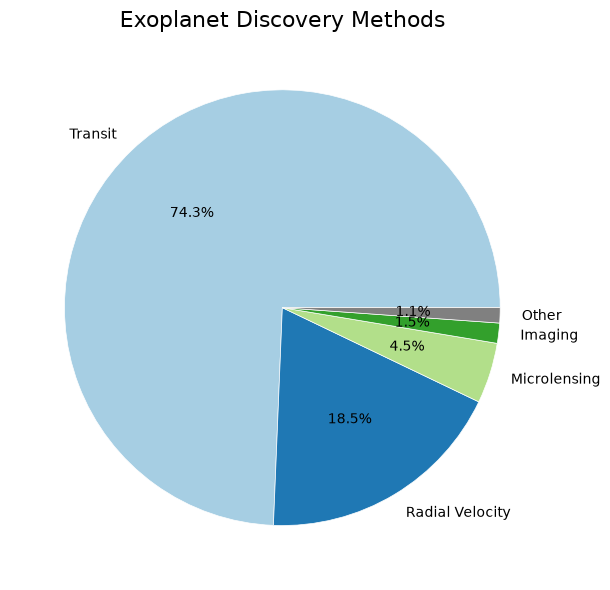

In [11]:
# Find the top 4 most common discovery methods
top_method_counts = method_counts.head(4)

# Set colours for discovery methods on graphs
method_colours = {
    method : colour
    for method, colour in zip(method_counts.index, plt.cm.Paired.colors)
}

method_colours['Other'] = '#808080'

# Create data for pie chart with top 4 methods and other methods condensed into "Other" for ease of viewing
method_counts_pie = top_method_counts
method_counts_pie['Other'] = method_counts.iloc[4:].sum()

# Plot a pie chart
plt.figure(figsize = (10,6))

plt.pie(method_counts_pie, labels = method_counts_pie.index,
        colors = [method_colours[method] for method in method_counts_pie.index],
        autopct = '%1.1f%%',
        wedgeprops = {'edgecolor': 'white', 'linewidth': 0.5},
        textprops = {'fontsize' : 10})
plt.title("Exoplanet Discovery Methods", fontsize = 16)

plt.tight_layout()
plt.show()

The transit detection method accounts for almost 75% of the detected exoplanets in the dataset. Radial velocity accounts for 18.5%, with other detection methods accounting for the rest.

## 4.2 Exoplanet Discoveries Over Time

Let's investigate how the number of exoplanet discoveries in the Planetary Systems dataset have changed over time.

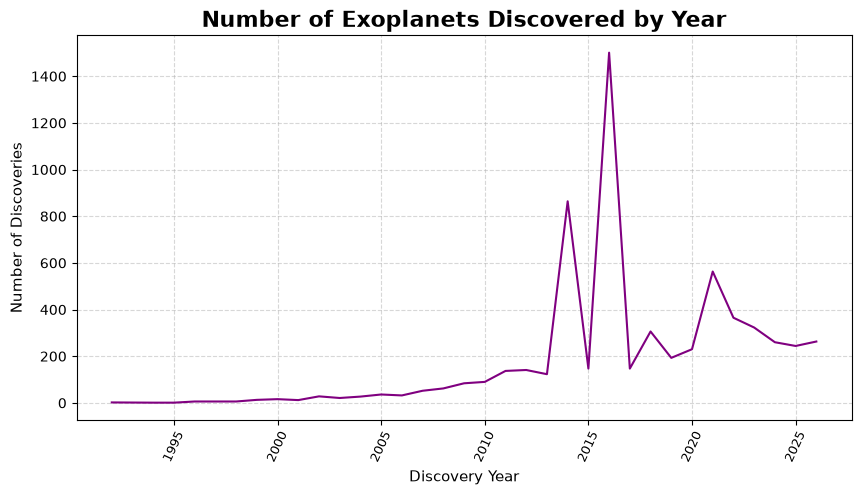

In [12]:
# Calculate how many exoplanet entries each year has in the dataset
year_counts = df_clean['disc_year'].value_counts().sort_index()

# Plot a line graph
year_counts.plot(kind = 'line', figsize = (10,5), color = 'purple')

plt.xlabel("Discovery Year", fontsize = 11)
plt.ylabel("Number of Discoveries", fontsize = 11)
plt.title("Number of Exoplanets Discovered by Year", fontsize = 16, fontweight = 'bold')

plt.grid(linestyle = '--', alpha = 0.5)
plt.xticks(rotation = 65, fontsize = 9)
plt.show()

We can see that overall, the number of exoplanets discovered annually has increased over the last few decades. There have been several large peaks over the years, most notably in 2016. Some of these peaks may be due to data from new space or ground-based telescopes.

We can see how this trend differs among detection methods using subplots.

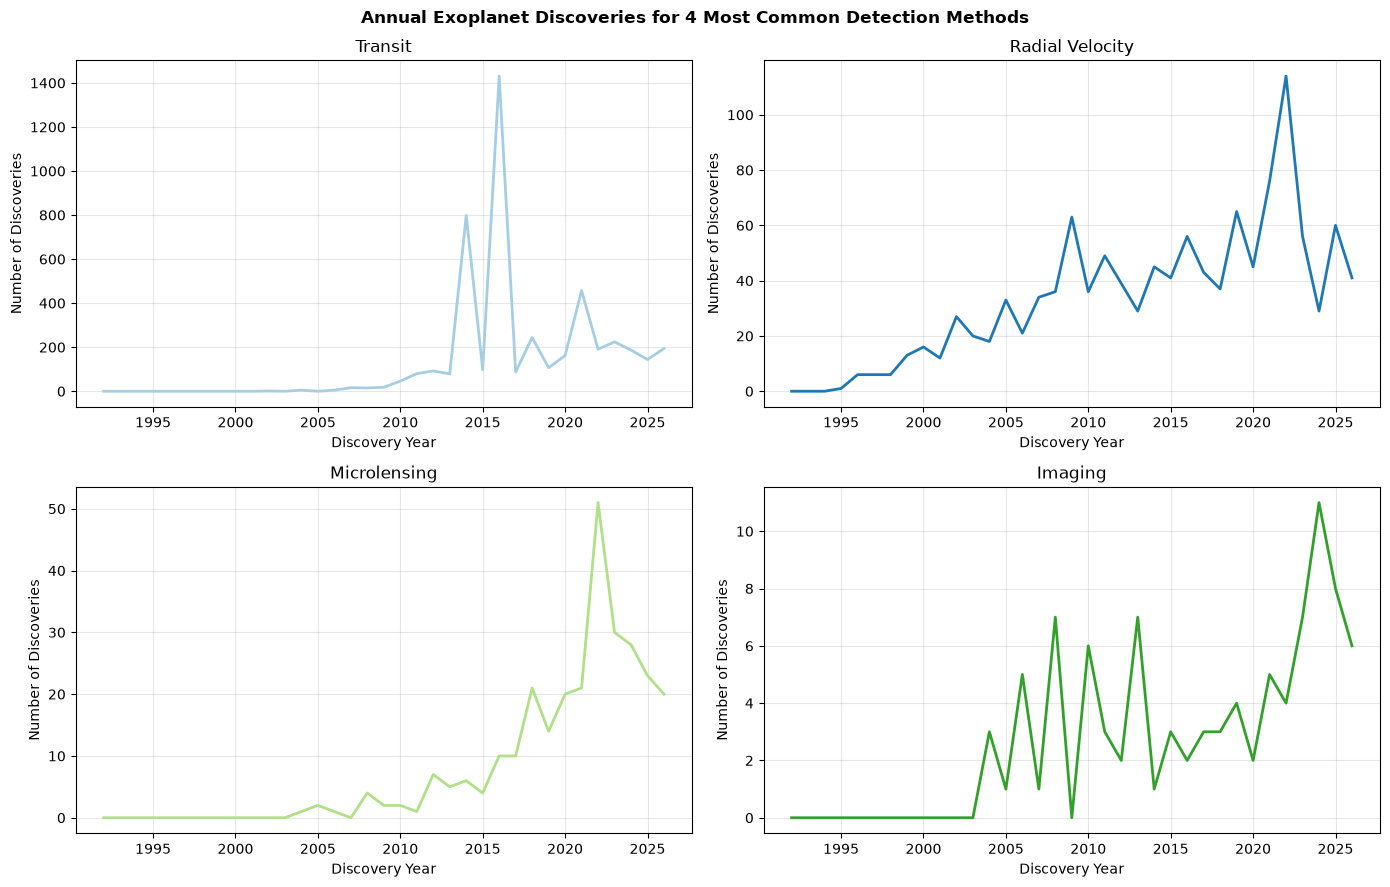

In [13]:
# Calculate the number of exoplanet discoveries by method and year
method_counts_year = (
    df_clean.groupby(['disc_year', 'discoverymethod'])
        .size()
        .reset_index(name = 'count')
)

# Format the data for plotting, making sure that each year is included for each method
plot_data = (
    method_counts_year
    .pivot(index = 'disc_year',
           columns = 'discoverymethod',
           values = 'count')
    .fillna(0)
)

# Create a list of top 4 discovery methods
top_methods = top_method_counts.index

# Plot a subplot for each of the top discovery methods
fig, axes = plt.subplots(2, 2, figsize = (14, 9))

for method, ax in zip(top_methods, axes.flatten()):
    plot_data[method].plot(
        ax = ax,
        linewidth = 2,
        color = method_colours[method]
    )

    ax.set_title(method)
    ax.set_xlabel("Discovery Year")
    ax.set_ylabel("Number of Discoveries")
    ax.grid(alpha = 0.3)

plt.suptitle("Annual Exoplanet Discoveries for 4 Most Common Detection Methods",
             fontsize = 12, fontweight = 'bold')
plt.tight_layout()
plt.show()

As transit is the most common detection method, it dominates the overall trend of discoveries over time. When plotting each discovery method separately, however, we can notice some interesting trends. All of the top 4 methods show overall increases in the number of discoveries over time. There also appear to be no discoveries in the data by microlensing or direct imaging before 2003.

Let's investigate the discovery facilities to see if they can account for the large peaks in the data.

In [14]:
# Determine most common discovery facilities
top_facilities = df_clean['disc_facility'].value_counts().head()
top_facilities

disc_facility
Kepler                                          2777
Transiting Exoplanet Survey Satellite (TESS)     927
K2                                               549
Multiple Observatories                           338
La Silla Observatory                             299
Name: count, dtype: int64

Kepler is the most common discovery facility, accounting for almost half of the discovered exoplanets in the cleaned dataset. We can see how discoveries from these top facilities have changed over time with a line graph.

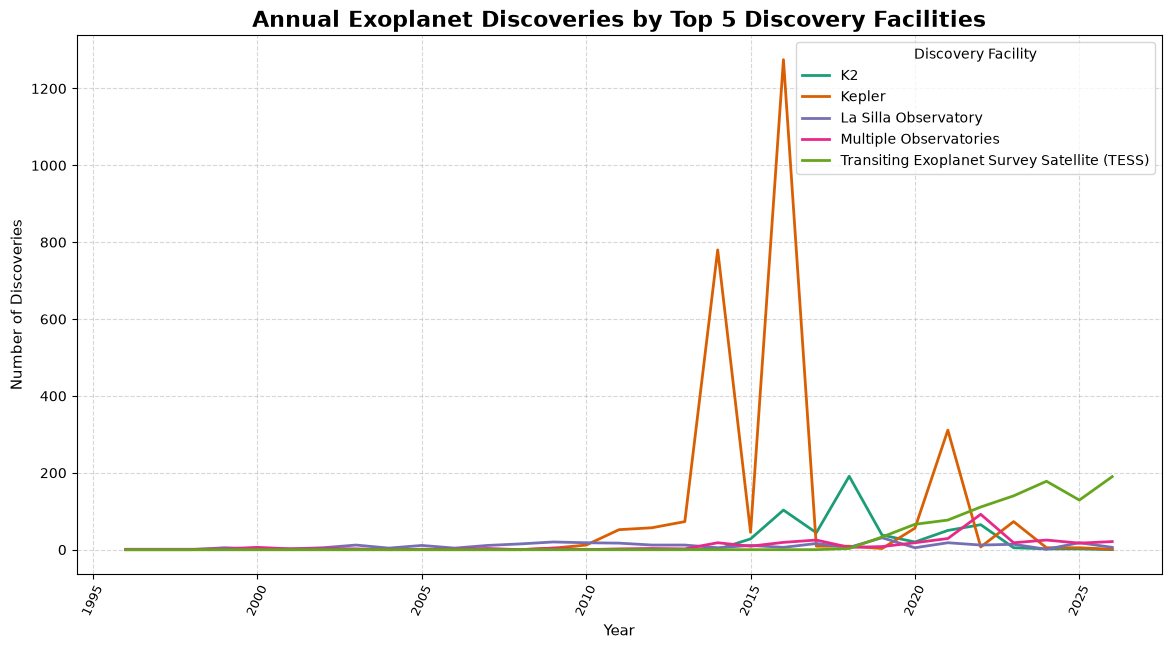

In [15]:
# Create plot data
facility_yearly = (
    df_clean[df_clean['disc_facility'].isin(top_facilities.index)]
    .groupby(['disc_year', 'disc_facility'])
    .size()
    .unstack(fill_value = 0)
)

# Plot a line graph
plt.figure(figsize = (14, 7))

colours = plt.cm.Dark2.colors

for facility, colour in zip(facility_yearly.columns, colours):
    plt.plot(
        facility_yearly.index,
        facility_yearly[facility],
        label = facility,
        linewidth = 2,
        color = colour
    )

plt.xlabel("Year", fontsize = 11)
plt.ylabel("Number of Discoveries", fontsize = 11)
plt.title("Annual Exoplanet Discoveries by Top 5 Discovery Facilities", fontsize = 16, fontweight = 'bold')

plt.legend(title = "Discovery Facility")
plt.grid(linestyle = '--', alpha = 0.5)
plt.xticks(rotation = 65, fontsize = 9)
plt.show()

Note that there are two large peaks in exoplanet discovery by Kepler in 2014 and 2016, and a smaller peak in 2021. These batches of discoveries account for the peaks in the overall number of annual discoveries.

## 4.3 Exoplanet Property distributions

Next, let's investigate the distributions of different exoplanet properties in the data such as radius, mass, and orbital period.

We can use a histogram to investigate the distribution of discovered exoplanet radii. Due to the huge variation in radii, a logarithmic scale has been used.

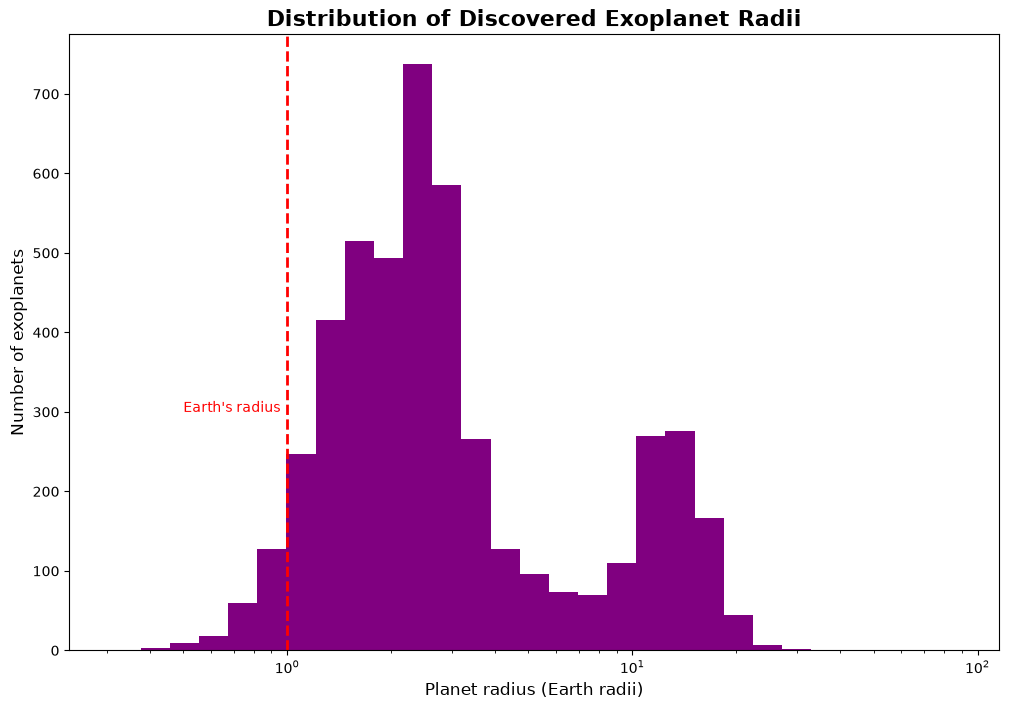

In [16]:
# Remove missing values of radius from the plot data
radii = df_clean["pl_rade"].dropna()

# Create logarithmic bins
bins = np.logspace(
        np.log10(radii.min()),
        np.log10(radii.max()),
        30
)

# Plot the histogram
plt.figure(figsize = (12,8))

plt.hist(radii, bins = bins, color = "purple")
plt.xscale("log")

# Plot a line to display the Earth's radius on the graph
plt.axvline(x = 1, color = "red", linewidth = 2, linestyle = "--")
plt.text(0.5, 300, "Earth's radius", color = "red")

plt.xlabel("Planet radius (Earth radii)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Radii", fontsize = 16, fontweight = "bold")

plt.show()

If we add a line to represent the radius of Earth, we can see that the vast majority of discovered exoplanets with measured radii are have larger radii than Earth. The largest planet in this dataset has a radius of 87 times that of the Earth. There also appear to be two populations of exoplanet shown by the two peaks present in the histogram. This could be due to measurements from different detection methods, or populations of different categories of exoplanet, or due to something else entirely.

Let's now investigate the distribution of orbital periods among the exoplanets in the data.

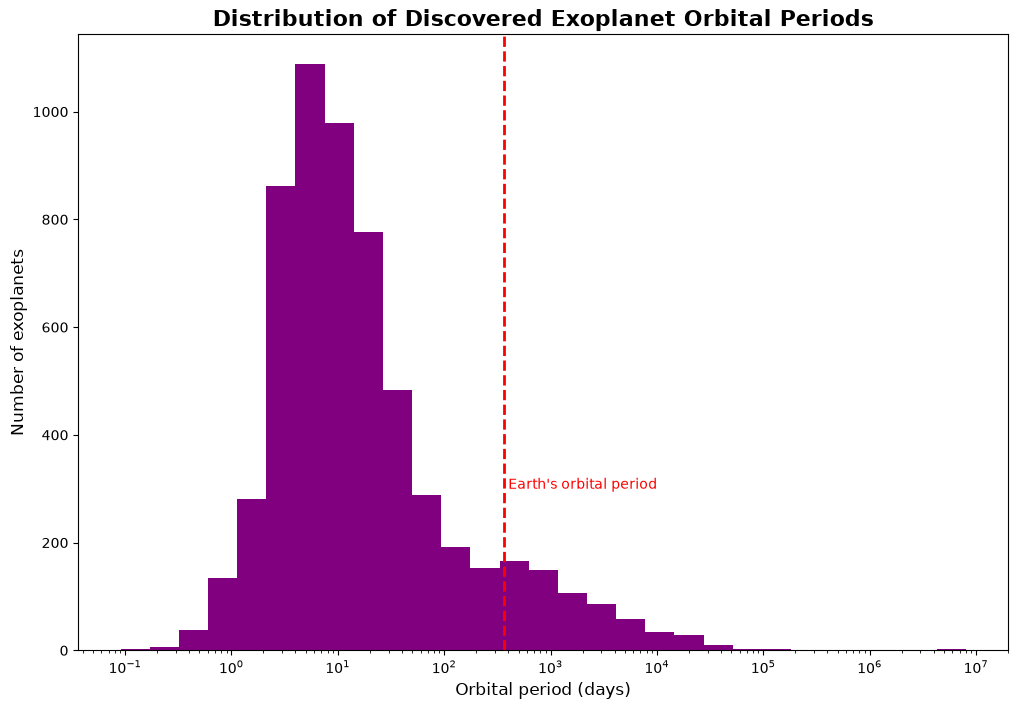

In [17]:
# Remove missing values of orbital period from the plot data
periods = df_clean['pl_orbper'].dropna()

# Create logarithmic bins
bins = np.logspace(
        np.log10(periods.min()),
        np.log10(periods.max()),
        30
)

# Plot the histogram
plt.figure(figsize = (12,8))

plt.hist(periods, bins = bins, color = 'purple')
plt.xscale('log')

# Plot a line representing the orbital period of the Earth
plt.axvline(x = 365.25, color = 'red', linewidth = 2, linestyle = '--')
plt.text(400, 300, "Earth's orbital period", color = 'red')

plt.xlabel("Orbital period (days)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Orbital Periods", fontsize = 16, fontweight = 'bold')

plt.show()

We can see that most of the discovered exoplanets in the data have orbital periods that are shorter than that of the Earth. This indicates that they are likely much closer to their host star than the Earth is to the Sun. There are notable exceptions to this, however, and the planet with the longest orbital period in the data (CFHTWIR-Oph 98 b) has a period of over 22,000 years.

Let's investigate the distribution of discovered exoplanet masses in the data.

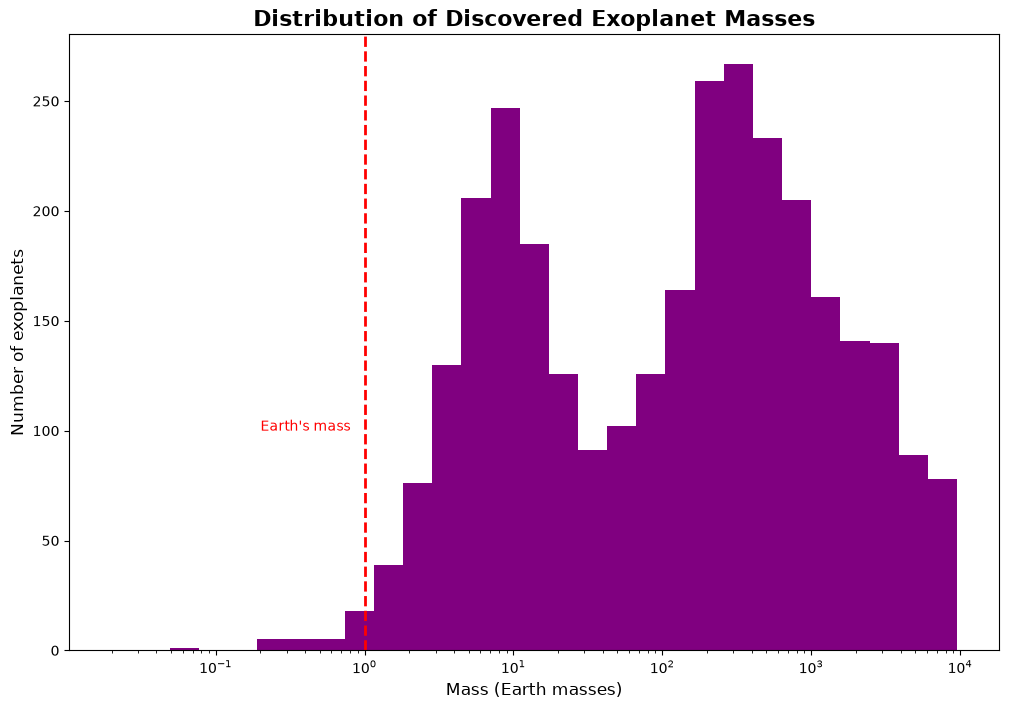

In [18]:
# Remove missing values of mass from the plot data
masses = df_clean['pl_bmasse'].dropna()

# Create logarithmic bins
bins = np.logspace(
        np.log10(masses.min()),
        np.log10(masses.max()),
        30
)

# Plot the histogram
plt.figure(figsize = (12,8))

plt.hist(masses, bins = bins, color = 'purple')
plt.xscale('log')

# Add a line to represent the mass of the Earth
plt.axvline(x = 1, color = 'red', linewidth = 2, linestyle = '--')
plt.text(0.2, 100, "Earth's mass", color = 'red')

plt.xlabel("Mass (Earth masses)", fontsize = 12)
plt.ylabel("Number of exoplanets", fontsize = 12)
plt.title("Distribution of Discovered Exoplanet Masses", fontsize = 16, fontweight = 'bold')

plt.show()

We can see that the vast majority of discovered exoplanets with measured masses are much heavier than the Earth. This makes sense as it is easier to measure the mass of a heavier exoplanet compared to a lighter one. Like in the histogram of measured radii, there appear to be two peaks in this histogram. This is potentially due to differing detection methods, or different populations of exoplanets, or perhaps something else entirely.

We can plot a stacked histograms of these three variables (radius, orbital period, and mass) to see if any of the characteristic peaks are due to detection method.

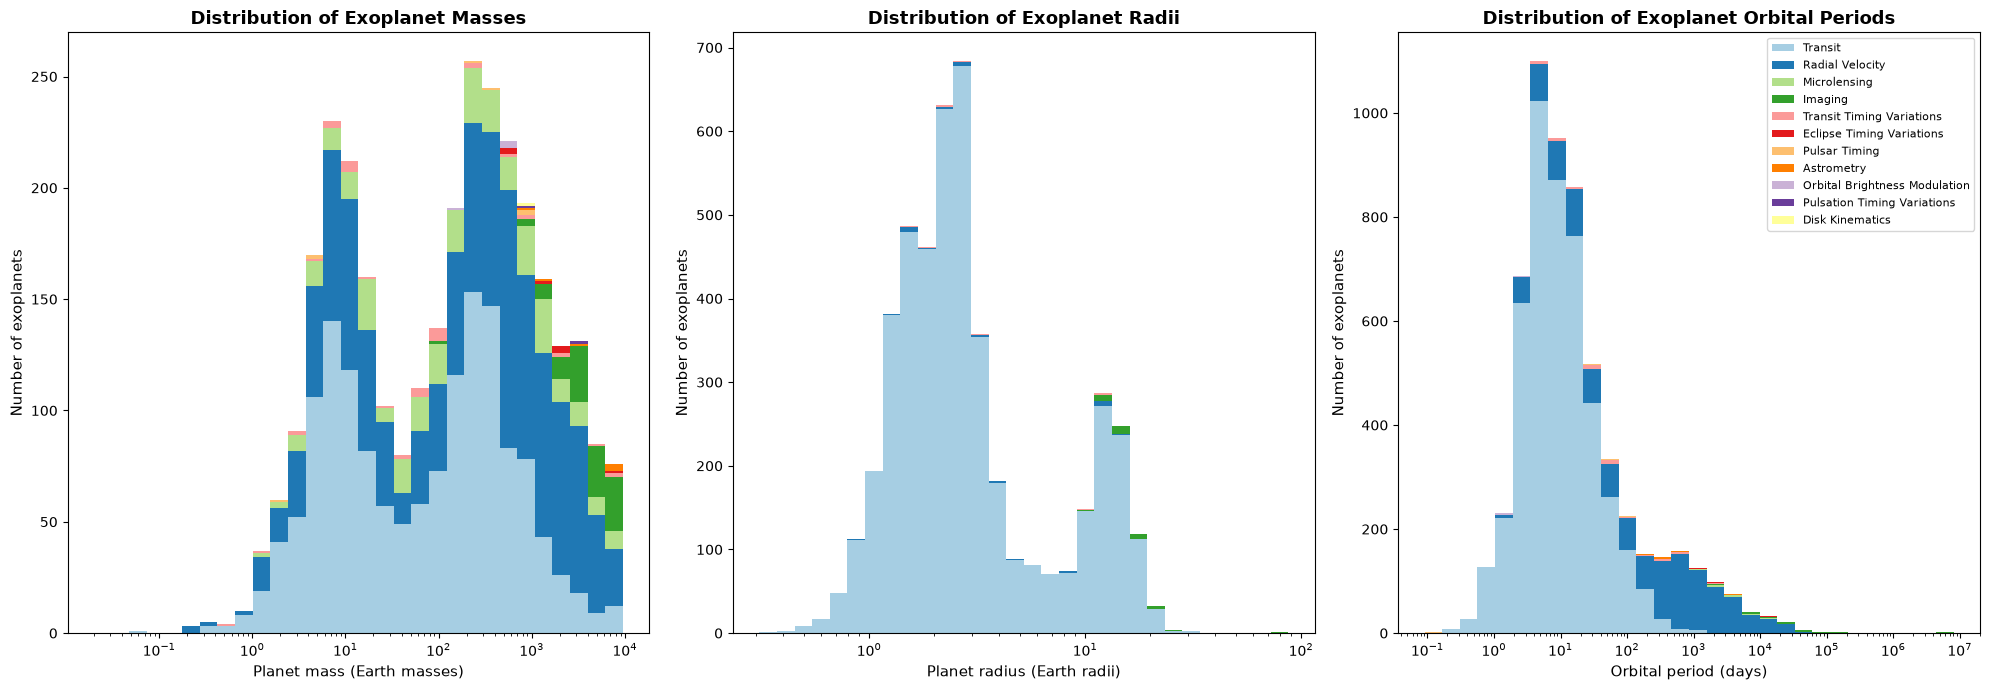

In [19]:
# Create a list of discovery methods in order of frequency
methods = df_clean['discoverymethod'].value_counts().index

# Select variables to plot
variables = ['pl_bmasse', 'pl_rade', 'pl_orbper']

# Set axis labels
labels = [
    "Planet mass (Earth masses)",
    "Planet radius (Earth radii)",
    "Orbital period (days)"
]

# Set graph titles
titles = [
    "Distribution of Exoplanet Masses",
    "Distribution of Exoplanet Radii",
    "Distribution of Exoplanet Orbital Periods"
]

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# Loop through variables and subplots
for ax, variable, label, title in zip(axes, variables, labels, titles):

    plot_data = []

    # Create groups for each discovery method
    for method in methods:
        values = df_clean.loc[
            df_clean['discoverymethod'] == method,
            variable
        ].dropna()

        plot_data.append(values)

    # Create logarithmic bins
    bins = np.logspace(
        np.log10(df_clean[variable].min()),
        np.log10(df_clean[variable].max()),
        31
    )

    # Plot stacked histogram
    ax.hist(
        plot_data,
        bins = bins,
        stacked = True,
        label = methods,
        color = [method_colours[method] for method in methods]
    )

    ax.set_xscale('log')
    ax.set_xlabel(label, fontsize = 11)
    ax.set_ylabel("Number of exoplanets", fontsize = 11)
    ax.set_title(title, fontsize=13, fontweight = 'bold')

# Add legend
axes[-1].legend(fontsize = 8)

plt.tight_layout()
plt.show()

These stacked histograms show that the two separate peaks in mass and radius are likely not due to different detection methods as the peaks exist in the data for each detection method in the mass distribution. Also, nearly all of the exoplanets in the data with measured radii were discovered through the transit method, so different detection methods cannot explain the two peaks in this data either. In the orbital period histogram, it seems that the radial velocity method favours exoplanets with longer periods, while the transit method favours planets with shorter periods. However, as there are much more planets discovered via the transit method compared to the radial velocity method, we cannot say this for certain.

## 4.4 Mass-Radius-Period Relationship

This next section covers an analysis of the relationship between the variables mass, radius, and period.

Let's first look at the linear correlations between the mass, radius, and orbital period of exoplanets in the data.

In [20]:
# Calculate correlation matrix
df_clean[
    ['pl_bmasse', 'pl_rade', 'pl_orbper']
].corr()

,pl_bmasse,pl_rade,pl_orbper
pl_bmasse,1.000000,0.360673,0.091159
pl_rade,0.360673,1.000000,0.061077
pl_orbper,0.091159,0.061077,1.000000


All three variables have positive correlations, meaning as one variable increases, so does the other. Mass and radius show the strongest correlation, with a Pearson correlation coefficient of 0.36 indicating a moderate positive correlation. Mass and orbital period, and radius and orbital period show very weak positive correlations with positive Pearson correlation coefficients below 0.1.

We can also calculate the log correlations of these variables.

In [21]:
# Calculate log correlation matrix
np.log10(df_clean[
    ['pl_bmasse', 'pl_rade', 'pl_orbper']
]).corr()

,pl_bmasse,pl_rade,pl_orbper
pl_bmasse,1.000000,0.862780,0.456978
pl_rade,0.862780,1.000000,0.039952
pl_orbper,0.456978,0.039952,1.000000


We can see that the logarithmic values have a stronger correlation for mass and radius, going from a Pearson correlation coefficient of 0.36 to 0.86, indicating a strong linear correlation when a logarithm is applied. The correlation between orbital period and mass also increases for the logarithmic values to 0.46 indicating a moderate positive correlation. The log correlation between orbital period and radius is the only one that decreases when compared to the non-log value indicating an extremely weak positive correlation.

We now have 3 subsections of the data on which we can perform an analysis.

We can plot these variables on scatter graphs to see them more visually. Before we plot, we need to find subsets subsets of the data that have values for these three variables, as there are many missing values in these columns.

In [22]:
# Find exoplanets that have a measured mass and a measured radius
mass_radius = df_clean.dropna(subset = ['pl_bmasse', 'pl_rade']).copy()

# Find exoplanets that have a measured period and a measured radius
period_radius = df_clean.dropna(subset = ['pl_orbper', 'pl_rade']).copy()

# Find exoplanets that have a measured period and a measured mass
period_mass = df_clean.dropna(subset = ['pl_orbper', 'pl_bmasse']).copy()

print("Mass and radius:", len(mass_radius))
print("Period and radius:", len(period_radius))
print("Period and mass:", len(period_mass))

Mass and radius: 1544
Period and radius: 4693
Period and mass: 2753


Now that we have three subsets of the data, we can plot out graphs. Note that these are much smaller than the overall size of the dataset, especially the mass-radius subset.

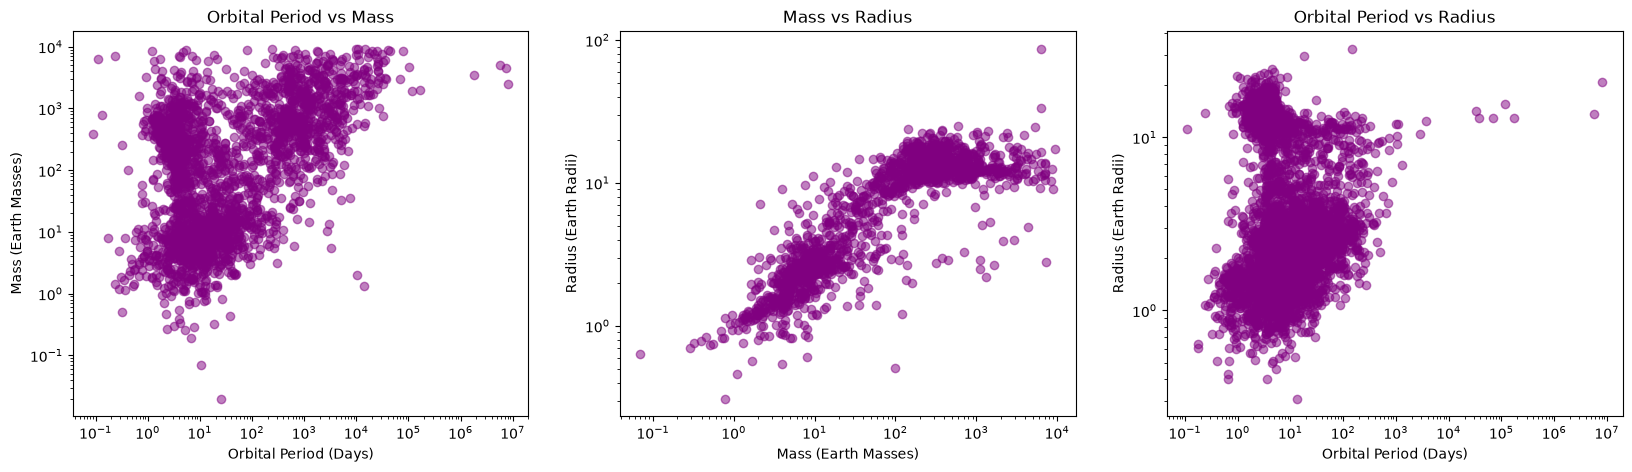

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot scatter graph of orbital period vs mass
axes[0].scatter(
    period_mass['pl_orbper'],
    period_mass['pl_bmasse'],
    alpha = 0.5,
    color = 'purple'
)

axes[0].set_title("Orbital Period vs Mass")
axes[0].set_xlabel("Orbital Period (Days)")
axes[0].set_ylabel("Mass (Earth Masses)")

# Plot scatter graph of mass vs radius
axes[1].scatter(
    mass_radius['pl_bmasse'],
    mass_radius['pl_rade'],
    alpha = 0.5,
    color = 'purple'
)

axes[1].set_title("Mass vs Radius")
axes[1].set_xlabel("Mass (Earth Masses)")
axes[1].set_ylabel("Radius (Earth Radii)")

# Plot scatter graph of orbital period vs radius
axes[2].scatter(
    period_radius['pl_orbper'],
    period_radius['pl_rade'],
    alpha = 0.5,
    color = 'purple'
)

axes[2].set_title("Orbital Period vs Radius")
axes[2].set_xlabel("Orbital Period (Days)")
axes[2].set_ylabel("Radius (Earth Radii)")

# Set axes to log scale
for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')
    
plt.show()

We can see from the correlation coefficient values that the mass-radius relationship is particularly strong, and plotting this on a scatter graph with logarithmic axes we can see this correlation clearly.

It is worth noting that a value for the mass of an exoplanet cannot always be accurately determined. This dataset contains a variable pl_bmassprov that indicates the provenance of the measured value for mass. If the inclination i of an exoplanet's orbit relative to Earth is unknown, then by measuring the radial velocity of the host star we can obtain a value of m*sin(i) where m is the mass of the exoplanet and i is its orbital inclination. As sin(i) can be a value of between 0 and 1, Msini values represent the minimum value of an exoplanet's mass. We can investigate how many mass values come from planets with unknown orbital inclinations by investigating pl_bmassprov.

In [24]:
# Find value counts of mass provenance in the original cleaned dataset
df_clean['pl_bmassprov'].value_counts()

pl_bmassprov
Mass              2143
Msini              950
Msin(i)/sin(i)       7
Name: count, dtype: int64

In [25]:
# Find value counts of mass provenance in mass-radius subset
mass_radius['pl_bmassprov'].value_counts()

pl_bmassprov
Mass              1537
Msini                5
Msin(i)/sin(i)       2
Name: count, dtype: int64

We can see that the number of mass values that use m*sin(i) values is relatively small in the mass-radius subset of our data.

We can investigate how big an effect these m*sin(i) values have on the calculated mass-radius correlation.

In [26]:
# Calculate original log correlation of mass-radius subset
original_correlation = np.log10(mass_radius["pl_rade"]).corr(
    np.log10(mass_radius["pl_bmasse"])
)

# Filter the mass-radius subset to exclude values that use m*sin(i)
mass_radius_filtered = mass_radius[mass_radius["pl_bmassprov"] == "Mass"].copy()

# Calculate log correlation of filtered mass-radius subset
filtered_correlation = np.log10(mass_radius_filtered["pl_rade"]).corr(
    np.log10(mass_radius_filtered["pl_bmasse"])
)

# Print correlation results
print("Original number of planets:", len(mass_radius))
print("Filtered number of planets:", len(mass_radius_filtered))
print("Original logarithmic correlation:", original_correlation)
print("Filtered logarithmic correlation:", filtered_correlation)
print("Difference:", filtered_correlation - original_correlation)

Original number of planets: 1544
Filtered number of planets: 1537
Original logarithmic correlation: 0.862780477068796
Filtered logarithmic correlation: 0.8620220145853359
Difference: -0.0007584624834601206


## 4.5 Discovery Method Biases

Let us now investigate the types of exoplanets that each discovery method favours.

In [27]:
average_properties = df_clean.groupby('discoverymethod').agg(
    mass_mean = ('pl_bmasse', 'mean'),
    mass_median = ('pl_bmasse', 'median'),
    mass_count = ('pl_bmasse', 'count'),

    radius_mean = ('pl_rade', 'mean'),
    radius_median = ('pl_rade', 'median'),
    radius_count = ('pl_rade', 'count'),

    period_mean = ('pl_orbper', 'mean'),
    period_median = ('pl_orbper', 'median'),
    period_count = ('pl_orbper', 'count')
)

average_properties

,mass_mean,mass_median,mass_count,radius_mean,radius_median,radius_count,period_mean,period_median,period_count
discoverymethod,,,,,,,,,
Astrometry,4673.610125,5021.688831,6,NaN,NaN,0,8.652617e+02,334.760000,6
Disk Kinematics,794.575000,794.575000,1,NaN,NaN,0,NaN,NaN,0
Eclipse Timing Variations,2144.200372,1754.694704,8,NaN,NaN,0,2.610594e+03,1110.000000,8
Imaging,4363.399523,3994.486000,93,18.539094,15.188169,30,1.075121e+06,33100.000000,22
Microlensing,841.478830,190.000000,283,NaN,NaN,0,4.282426e+03,3285.000000,11
Orbital Brightness Modulation,525.212243,637.247557,4,15.244240,15.244240,1,2.153653e+00,1.887540,4
Pulsar Timing,278.155529,128.471533,8,NaN,NaN,0,1.475795e+03,25.262000,7
Pulsation Timing Variations,2383.725000,2383.725000,2,NaN,NaN,0,1.005000e+03,1005.000000,2
Radial Velocity,965.903803,296.853220,1163,4.824904,2.620000,30,1.725874e+03,307.900000,1165


We can see that there are quite a few discovery methods that have missing values for radius.

We can plot these properties using a bar chart to see what kind of exoplanets are favoured by each discovery method.

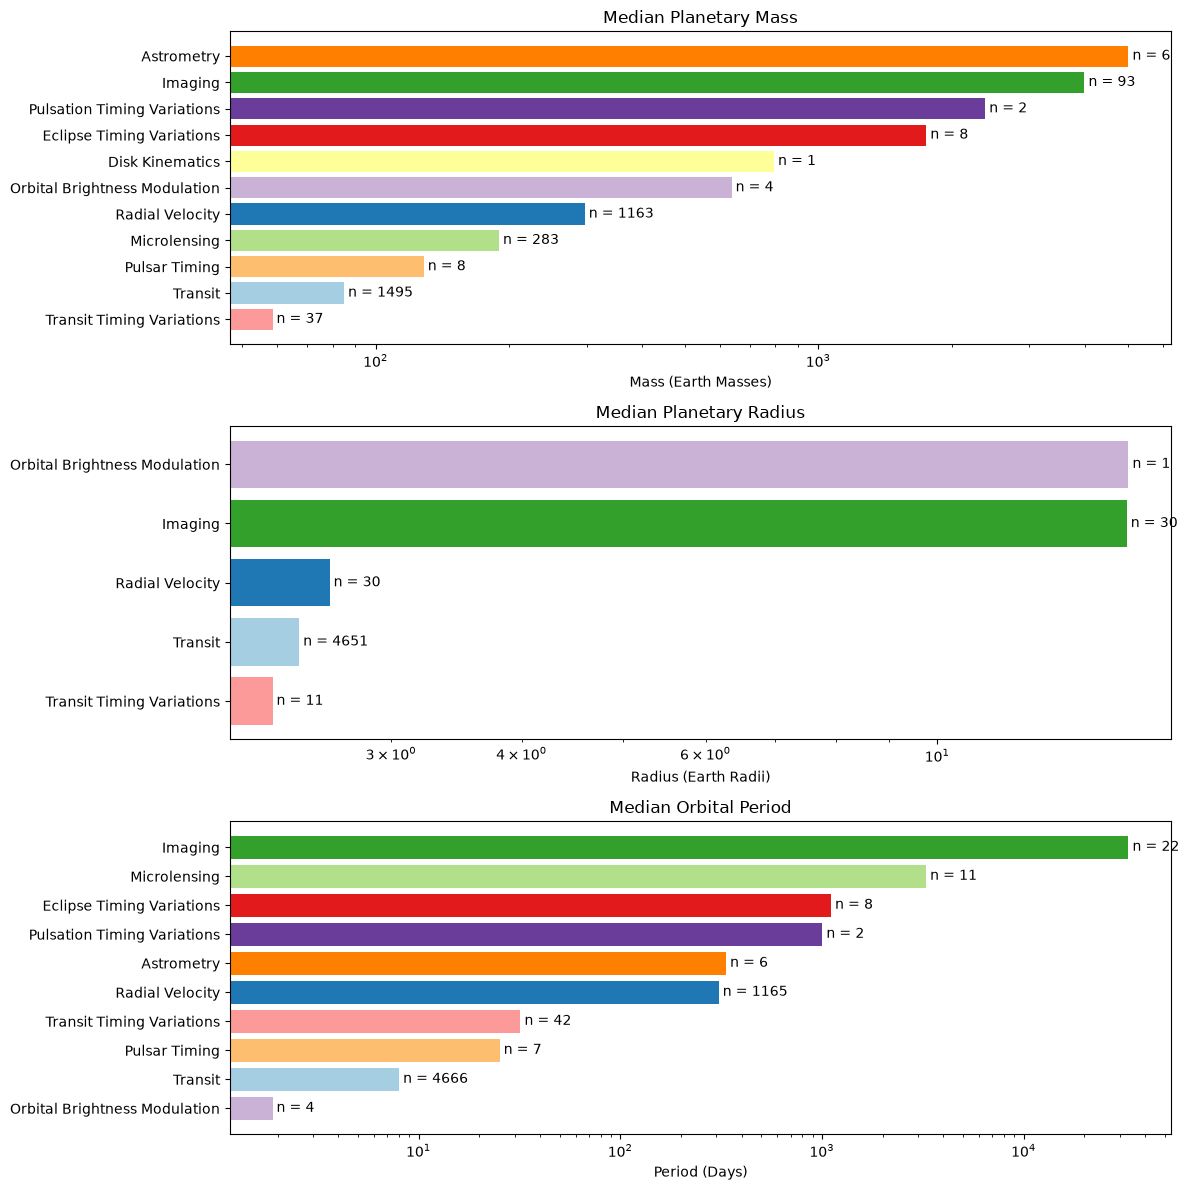

In [28]:
# Plot subplots
fig, axes = plt.subplots(3, 1, figsize = (12,12))

properties = [
    ('mass_median', 'mass_count', "Median Planetary Mass", "Mass (Earth Masses)"),
    ('radius_median', 'radius_count', "Median Planetary Radius", "Radius (Earth Radii)"),
    ('period_median', 'period_count', "Median Orbital Period", "Period (Days)")
]

# Loop through suplots and properties
for ax, (value, count, title, xlabel) in zip(axes, properties):

    # Sort data by plotted variable
    data = average_properties.sort_values(value)

    # Plot bars
    bars = ax.barh(
        data.index,
        data[value],
        color = [method_colours.get(method) for method in data.index]
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xscale('log')

    # Plot count labels
    for bar, n in zip(bars, data[count]):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f' n = {n}',
            va = 'center'
        )

plt.tight_layout()
plt.show()

It seems that exoplanets discovered by direct imaging have consistently large masses, radii, and orbital periods. This makes sense as a planet would need to be large and far from its host star in order to be visible from Earth and directly imaged.
Exoplanets detected by the transit method are relatively smaller and have shorter periods. This makes sense as planets with shorter periods will transit in front of their host stars more frequently and so be more easily detected using this method.
The median properties for exoplanets discovered by the radial velocity method sit in in between the median properties for direct imaging and transit.
Note that apart from transit and radial velocity, all other methods account for very few values and so these graphs may not accurately represent the biases of these methods.

# 5. Key Findings

1. The most common detection method in the data was found to be the transit method, accounting for about 3/4 of the exoplanets in the data. Radial velocity was the second most common detection method, accounting for around 18.5% with microlensing and direct imaging being the next two most common detection methods. The remaining detection methods only accounted for around 1% of the exoplanets in the data.
2. The number of exoplanet discoveries has increased over time. There have been several large peaks in the number of discoveries largely due to batches of discoveries from the Kepler space telescope.
3. The data is populated mostly by exoplanets that are more massive, have larger radii, and have shorter orbital periods than the Earth. There appear to be two distinct populations of exoplanets in the mass and radius distributions, potentially indicating different categories of planet (e.g.: super Earths and sub-Neptunes).
4. Mass and radius are strongly positively correlated indicating that as one variable increases, so does the other.
5. Different discovery methods favour different types of exoplanet. For example: direct imaging favours large, massive planets orbiting far away from their host stars, while the transit method favours smaller planets orbiting much closer.

# 6. Conclusion

It is important to note that the data represents only exoplanets that have been detected up to now and is strongly biased by detection methods. This means it is not necessarily an accurate representation of the properties of extra-solar planets in general.
Some detection methods have very few associated detections and so it may be unreliable to assume trends based on so few detections.